## EDA del dataset etiquetado de noticias económicas

En este cuaderno haremos un Análisis Exploratorio de Datos (EDA) del archivo `noticias_etiquetadas.csv`. El objetivo es entender:

- **Calidad del dataset**: estructura, tipos de datos, valores faltantes y duplicados.
- **Distribución de etiquetas**: equilibrio entre noticias positivas (1), neutras (0) y negativas (-1).
- **Características textuales**: longitud de títulos y descripciones y cómo varían por etiqueta.
- **Relevancia para modelado**: validar que el dataset es razonable como base de entrenamiento/validación para un modelo tipo BERT financiero en español.

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo gráfico con colores suaves / pasteles
sns.set(style="whitegrid", palette="pastel")
plt.rcParams["figure.figsize"] = (8, 5)

# Cargar noticias_etiquetadas.csv (incluido en este repositorio)
ruta_csv = "noticias_etiquetadas.csv"

df = pd.read_csv(ruta_csv)
df = df.iloc[:518].copy()
df.head()

,sentimiento,titulo,fecha,descripcion,url,id_unico,nombre_archivo
0,-1,Actividad industrial cayó 1.1% en enero y romp...,2026-03-13 14:50:48,Se observaron retrocesos en todos los componen...,https://www.eleconomista.com.mx/empresas/activ...,19bfe554-6d25-40fb-aa87-1144f7ba35d5,noticias_eleconomista_rss_20260314_021523.csv
1,-1,Bolsa mexicana retrocede; acciones de mineras ...,2026-03-13 15:23:03,Los índices accionarios locales bajan por segu...,https://www.eleconomista.com.mx/mercados/bolsa...,0dd04f55-79c0-4ef0-bad2-12e314530258,noticias_eleconomista_rss_20260314_021523.csv
2,1,Peso mexicano recupera terreno frente al dólar,2026-03-13 16:54:36,El peso recupera terreno después de una jornad...,https://www.eleconomista.com.mx/videos/peso-me...,f085c5ba-c0a0-476a-a373-c036d76de4e2,noticias_eleconomista_rss_20260314_021523.csv
3,1,Ecuador anuncia millonaria inversión de Améric...,2026-03-13 18:17:55,El Gobierno de ⁠Ecuador dijo este viernes que ...,https://www.eleconomista.com.mx/empresas/ecuad...,d586717d-29e2-40ee-9585-a51b4b1afe03,noticias_eleconomista_rss_20260314_021523.csv
4,1,Expectativas de empleo en México aumentan prev...,2026-03-13 19:20:35,El Mundial 2026 será un catalizador para el em...,https://www.eleconomista.com.mx/videos/expecta...,e79e8e72-856a-460c-8e55-65016b0fedb1,noticias_eleconomista_rss_20260314_021523.csv


### 1. Inspección inicial de la estructura del dataset

En esta sección revisamos:

- Dimensiones del dataset (número de noticias y columnas).
- Tipos de datos por columna.
- Presencia de valores faltantes.
- Posibles filas duplicadas según `id_unico` o combinación de `titulo` + `descripcion`.

Esto nos ayuda a evaluar si se requiere limpieza previa antes de usar el dataset para modelado.

In [31]:
# Dimensiones del dataset
print("Dimensiones (filas, columnas):", df.shape)

# Tipos de datos
display(df.dtypes)

# Valores faltantes por columna
print("\nValores faltantes por columna:")
print(df.isna().sum())

# Revisar duplicados por id_unico
duplicados_id = df["id_unico"].duplicated().sum()
print(f"\nFilas con id_unico duplicado: {duplicados_id}")

# Revisar duplicados por combinación titulo + descripcion
duplicados_texto = df.duplicated(subset=["titulo", "descripcion"]).sum()
print(f"Filas con (titulo, descripcion) duplicados: {duplicados_texto}")

Dimensiones (filas, columnas): (517, 7)


sentimiento       int64
titulo              str
fecha               str
descripcion         str
url                 str
id_unico            str
nombre_archivo      str
dtype: object


Valores faltantes por columna:
sentimiento       0
titulo            0
fecha             0
descripcion       1
url               0
id_unico          0
nombre_archivo    0
dtype: int64

Filas con id_unico duplicado: 0
Filas con (titulo, descripcion) duplicados: 0


### 2. Distribución de etiquetas de sentimiento

Las etiquetas de `sentimiento` están definidas como:

- **1**: positivo
- **0**: neutro
- **-1**: negativo

Aquí analizamos el conteo absoluto y la proporción de cada etiqueta.

Conteo de etiquetas:
sentimiento
-1    134
 0    182
 1    201
Name: count, dtype: int64

Proporciones:
sentimiento
-1    0.259
 0    0.352
 1    0.389
Name: count, dtype: float64


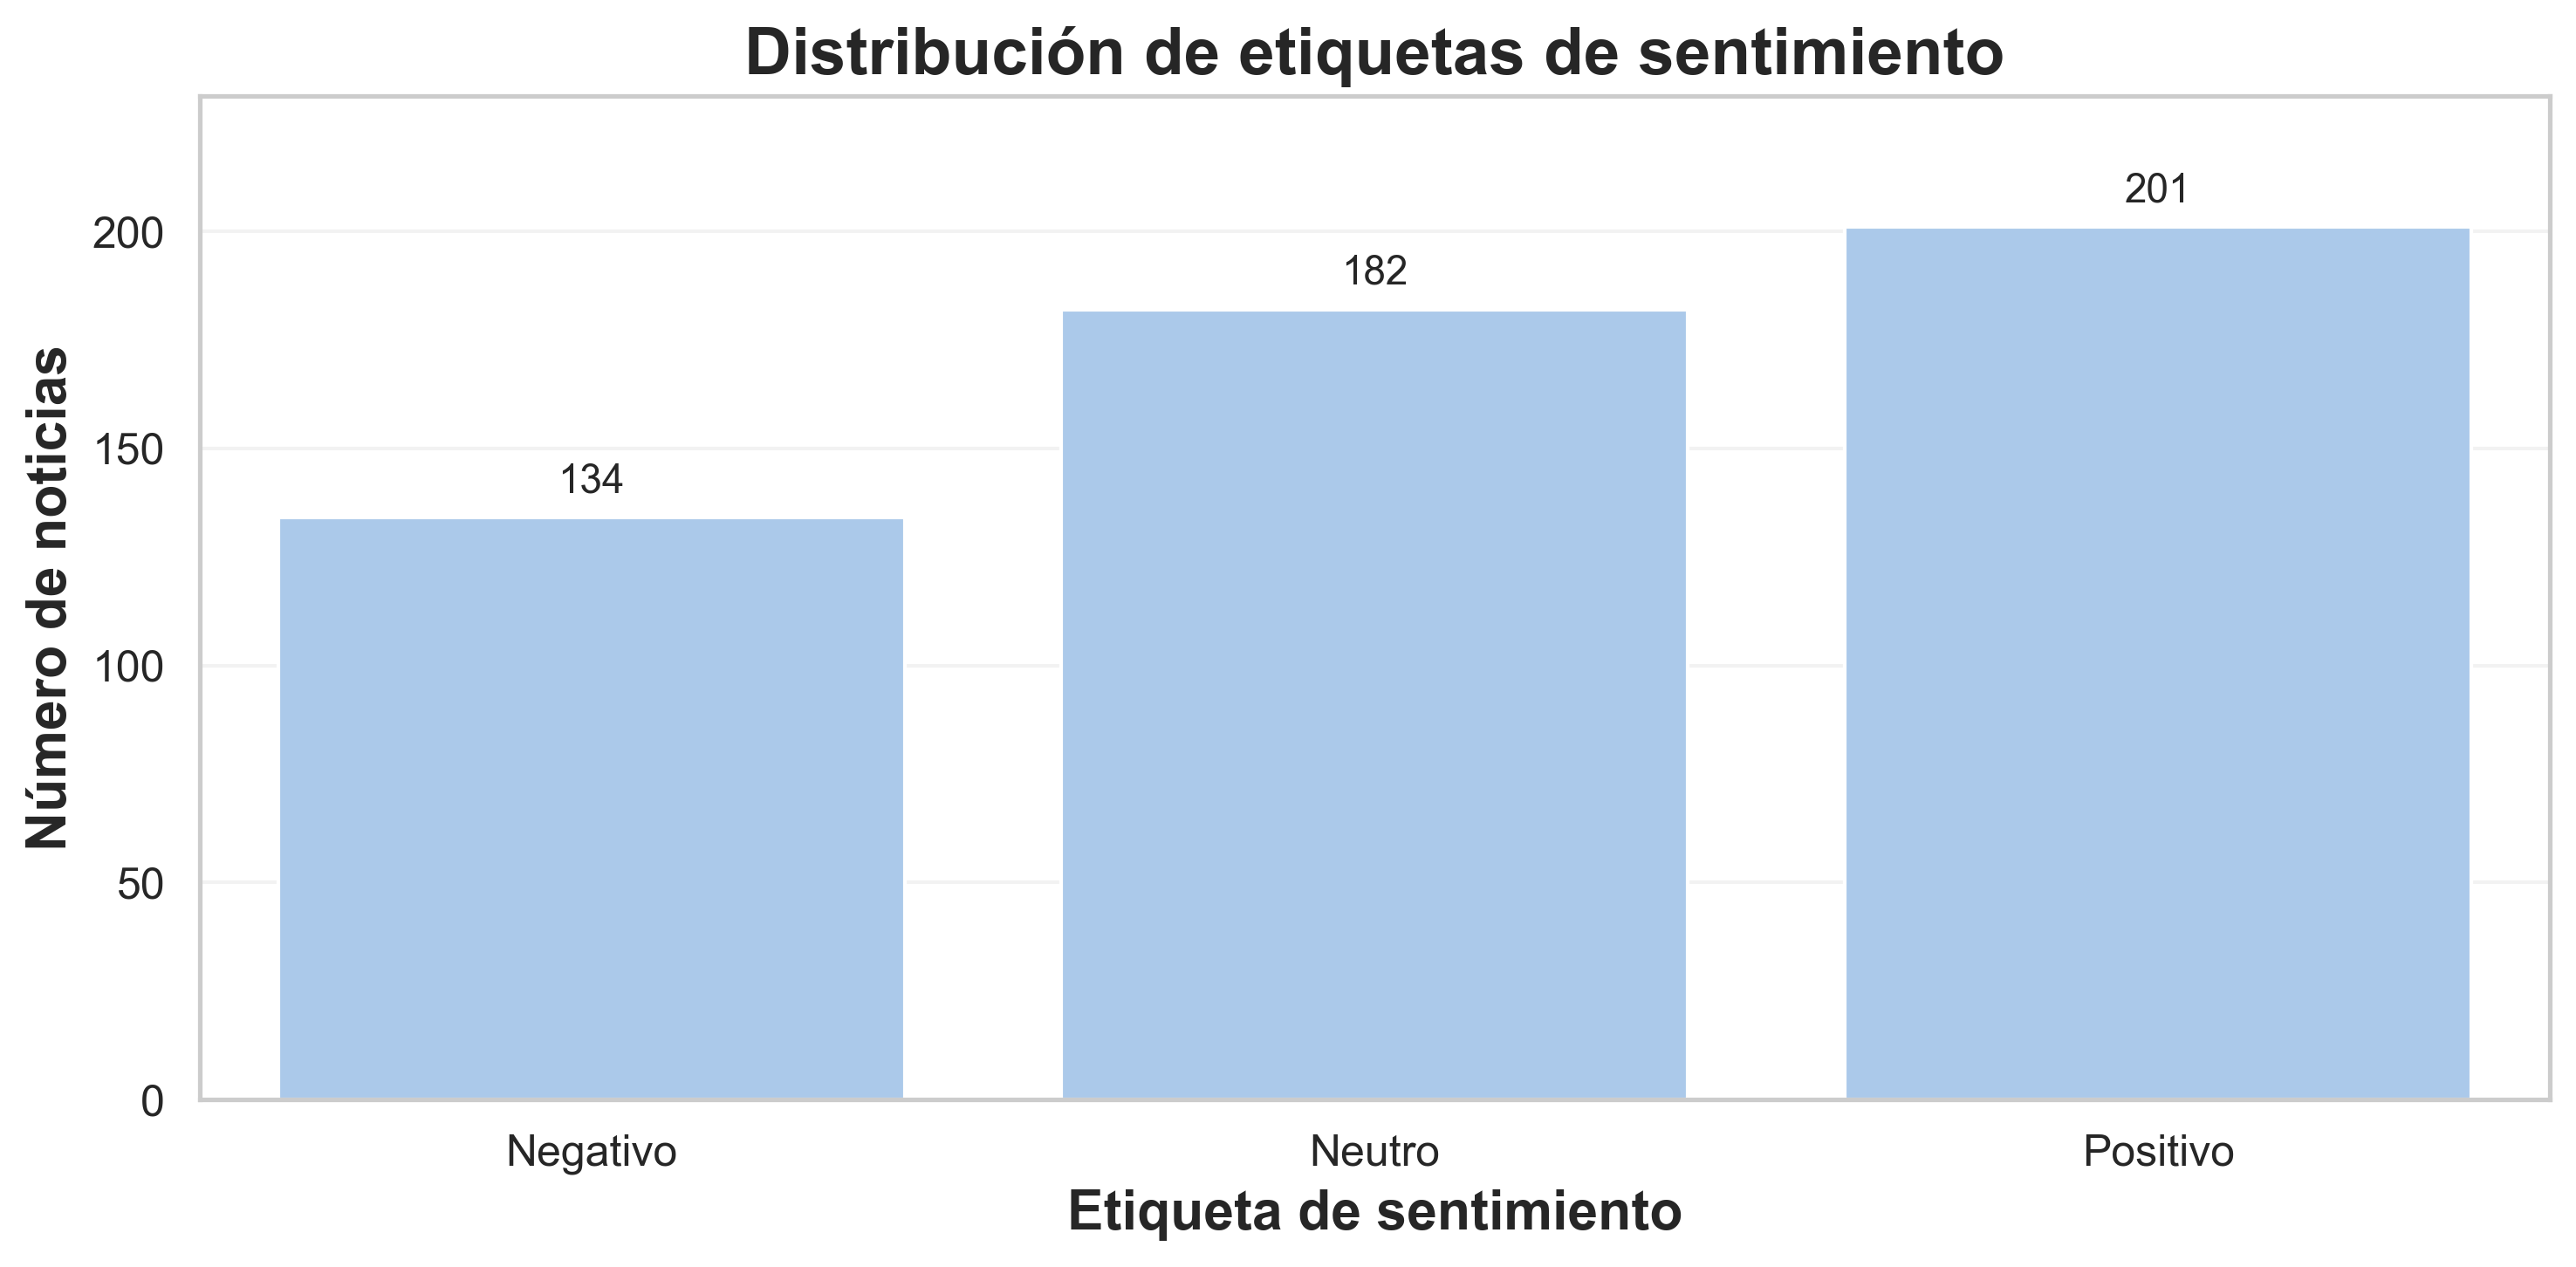

In [32]:
# Conteo de etiquetas
tabla_sent = df["sentimiento"].value_counts().sort_index()
proporciones = (tabla_sent / len(df)).round(3)

print("Conteo de etiquetas:")
print(tabla_sent)
print("\nProporciones:")
print(proporciones)

# Mapa de etiquetas a nombres legibles
mapa_labels = {-1: "Negativo", 0: "Neutro", 1: "Positivo"}
labels_legibles = [mapa_labels.get(i, str(i)) for i in tabla_sent.index]

# Gráfica de barras (mejor calidad y escala)
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax = sns.barplot(x=labels_legibles, y=tabla_sent.values, ax=ax)

ax.set_xlabel("Etiqueta de sentimiento", fontweight="bold", fontsize=15)
ax.set_ylabel("Número de noticias", fontweight="bold", fontsize=15)
ax.set_title(
    "Distribución de etiquetas de sentimiento", fontsize=18, fontweight="bold"
)

# Escala: partir desde 0 y dejar margen superior proporcional
ax.set_ylim(0, tabla_sent.max() * 1.15)
ax.tick_params(axis="both", labelsize=12)
ax.grid(axis="y", alpha=0.25)

# Mostrar valores en cada barra (mejora lectura)
for i, v in enumerate(tabla_sent.values):
    ax.text(i, v + tabla_sent.max() * 0.02, str(v), ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

### 3. Longitud de textos (título y descripción)

Para un modelo BERT, la longitud de las secuencias es relevante:

- Secuencias muy cortas pueden aportar poca información.
- Secuencias muy largas pueden requerir truncamiento o ajustes en el máximo de tokens.

Calculamos:

- Longitud en caracteres de `titulo` y de `descripcion`.
- Distribuciones generales.
- Comparación de longitudes por etiqueta de sentimiento.


       n_tokens_titulo  n_tokens_descripcion
count       517.000000            517.000000
mean         18.425532             43.090909
std           4.604595             24.899983
min           6.000000              0.000000
25%          15.000000             31.000000
50%          18.000000             38.000000
75%          21.000000             49.000000
max          34.000000            385.000000


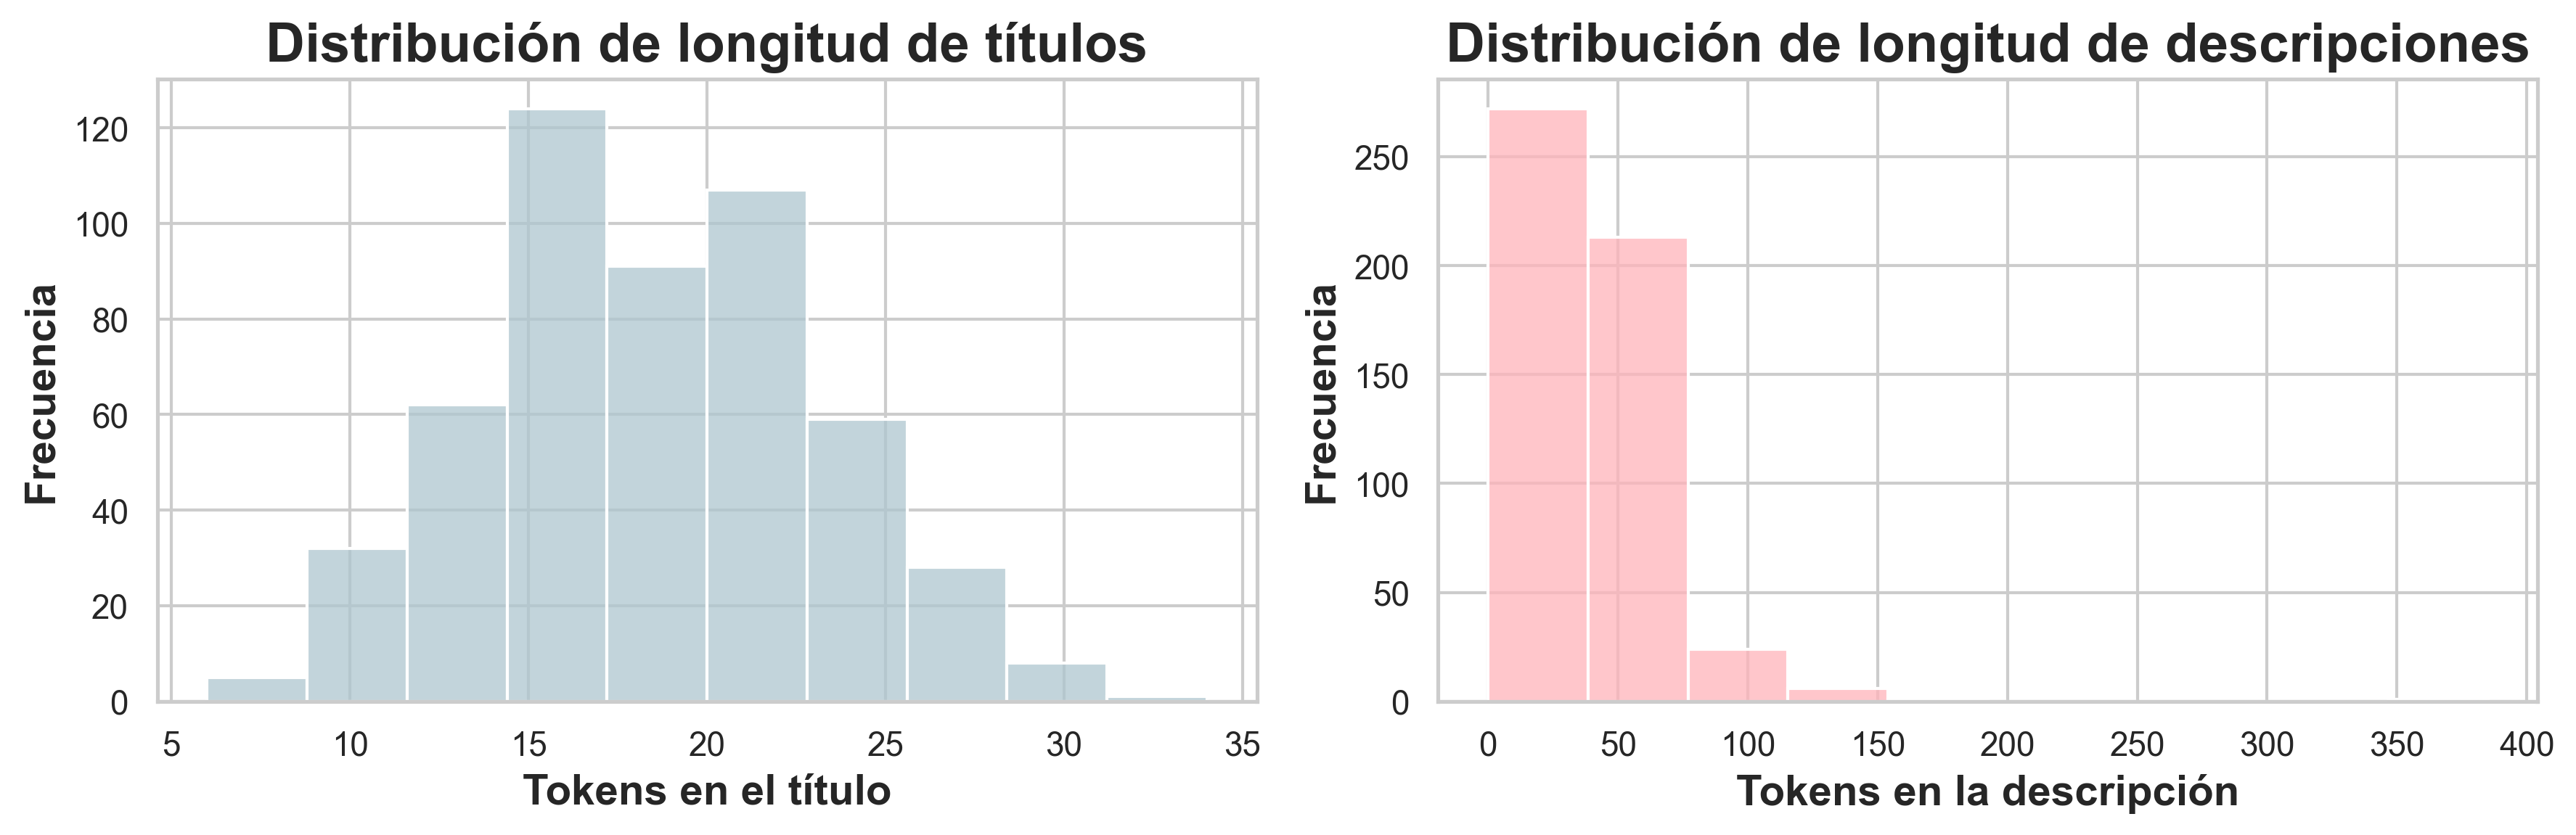

In [33]:
# Longitud de textos en tokens (según un tokenizer BERT en español)
# - Sirve para verificar si títulos/descripciones caben en el límite típico de modelos tipo BERT.
# - Se usa el mismo tokenizador que después se emplea para truncar a 80 tokens.
from transformers import AutoTokenizer

_tokenizer = AutoTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")


def contar_tokens(texto, tokenizer):
    """Cuenta tokens BERT; devuelve 0 si el texto está vacío/NaN."""
    if pd.isna(texto) or not str(texto).strip():
        return 0
    return len(tokenizer.encode(str(texto), add_special_tokens=True))


# Crear columnas con número de tokens para título y descripción
df["n_tokens_titulo"] = df["titulo"].fillna("").apply(lambda t: contar_tokens(t, _tokenizer))
df["n_tokens_descripcion"] = df["descripcion"].fillna("").apply(lambda t: contar_tokens(t, _tokenizer))

# Resumen estadístico (media, percentiles, etc.)
print(df[["n_tokens_titulo", "n_tokens_descripcion"]].describe())

# Histogramas para ver la distribución (colores pasteles del notebook)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=300)

sns.histplot(df["n_tokens_titulo"], bins=10, kde=False, ax=axes[0], color="#AEC6CF")  # azul pastel
axes[0].set_title("Distribución de longitud de títulos", fontsize=18, fontweight="bold")
axes[0].set_xlabel("Tokens en el título", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Frecuencia", fontsize=14, fontweight="bold")

sns.histplot(df["n_tokens_descripcion"], bins=10, kde=False, ax=axes[1], color="#FFB3BA")  # rosa pastel
axes[1].set_title("Distribución de longitud de descripciones", fontsize=18, fontweight="bold")
axes[1].set_xlabel("Tokens en la descripción", fontsize=14, fontweight="bold")
axes[1].set_ylabel("Frecuencia", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()


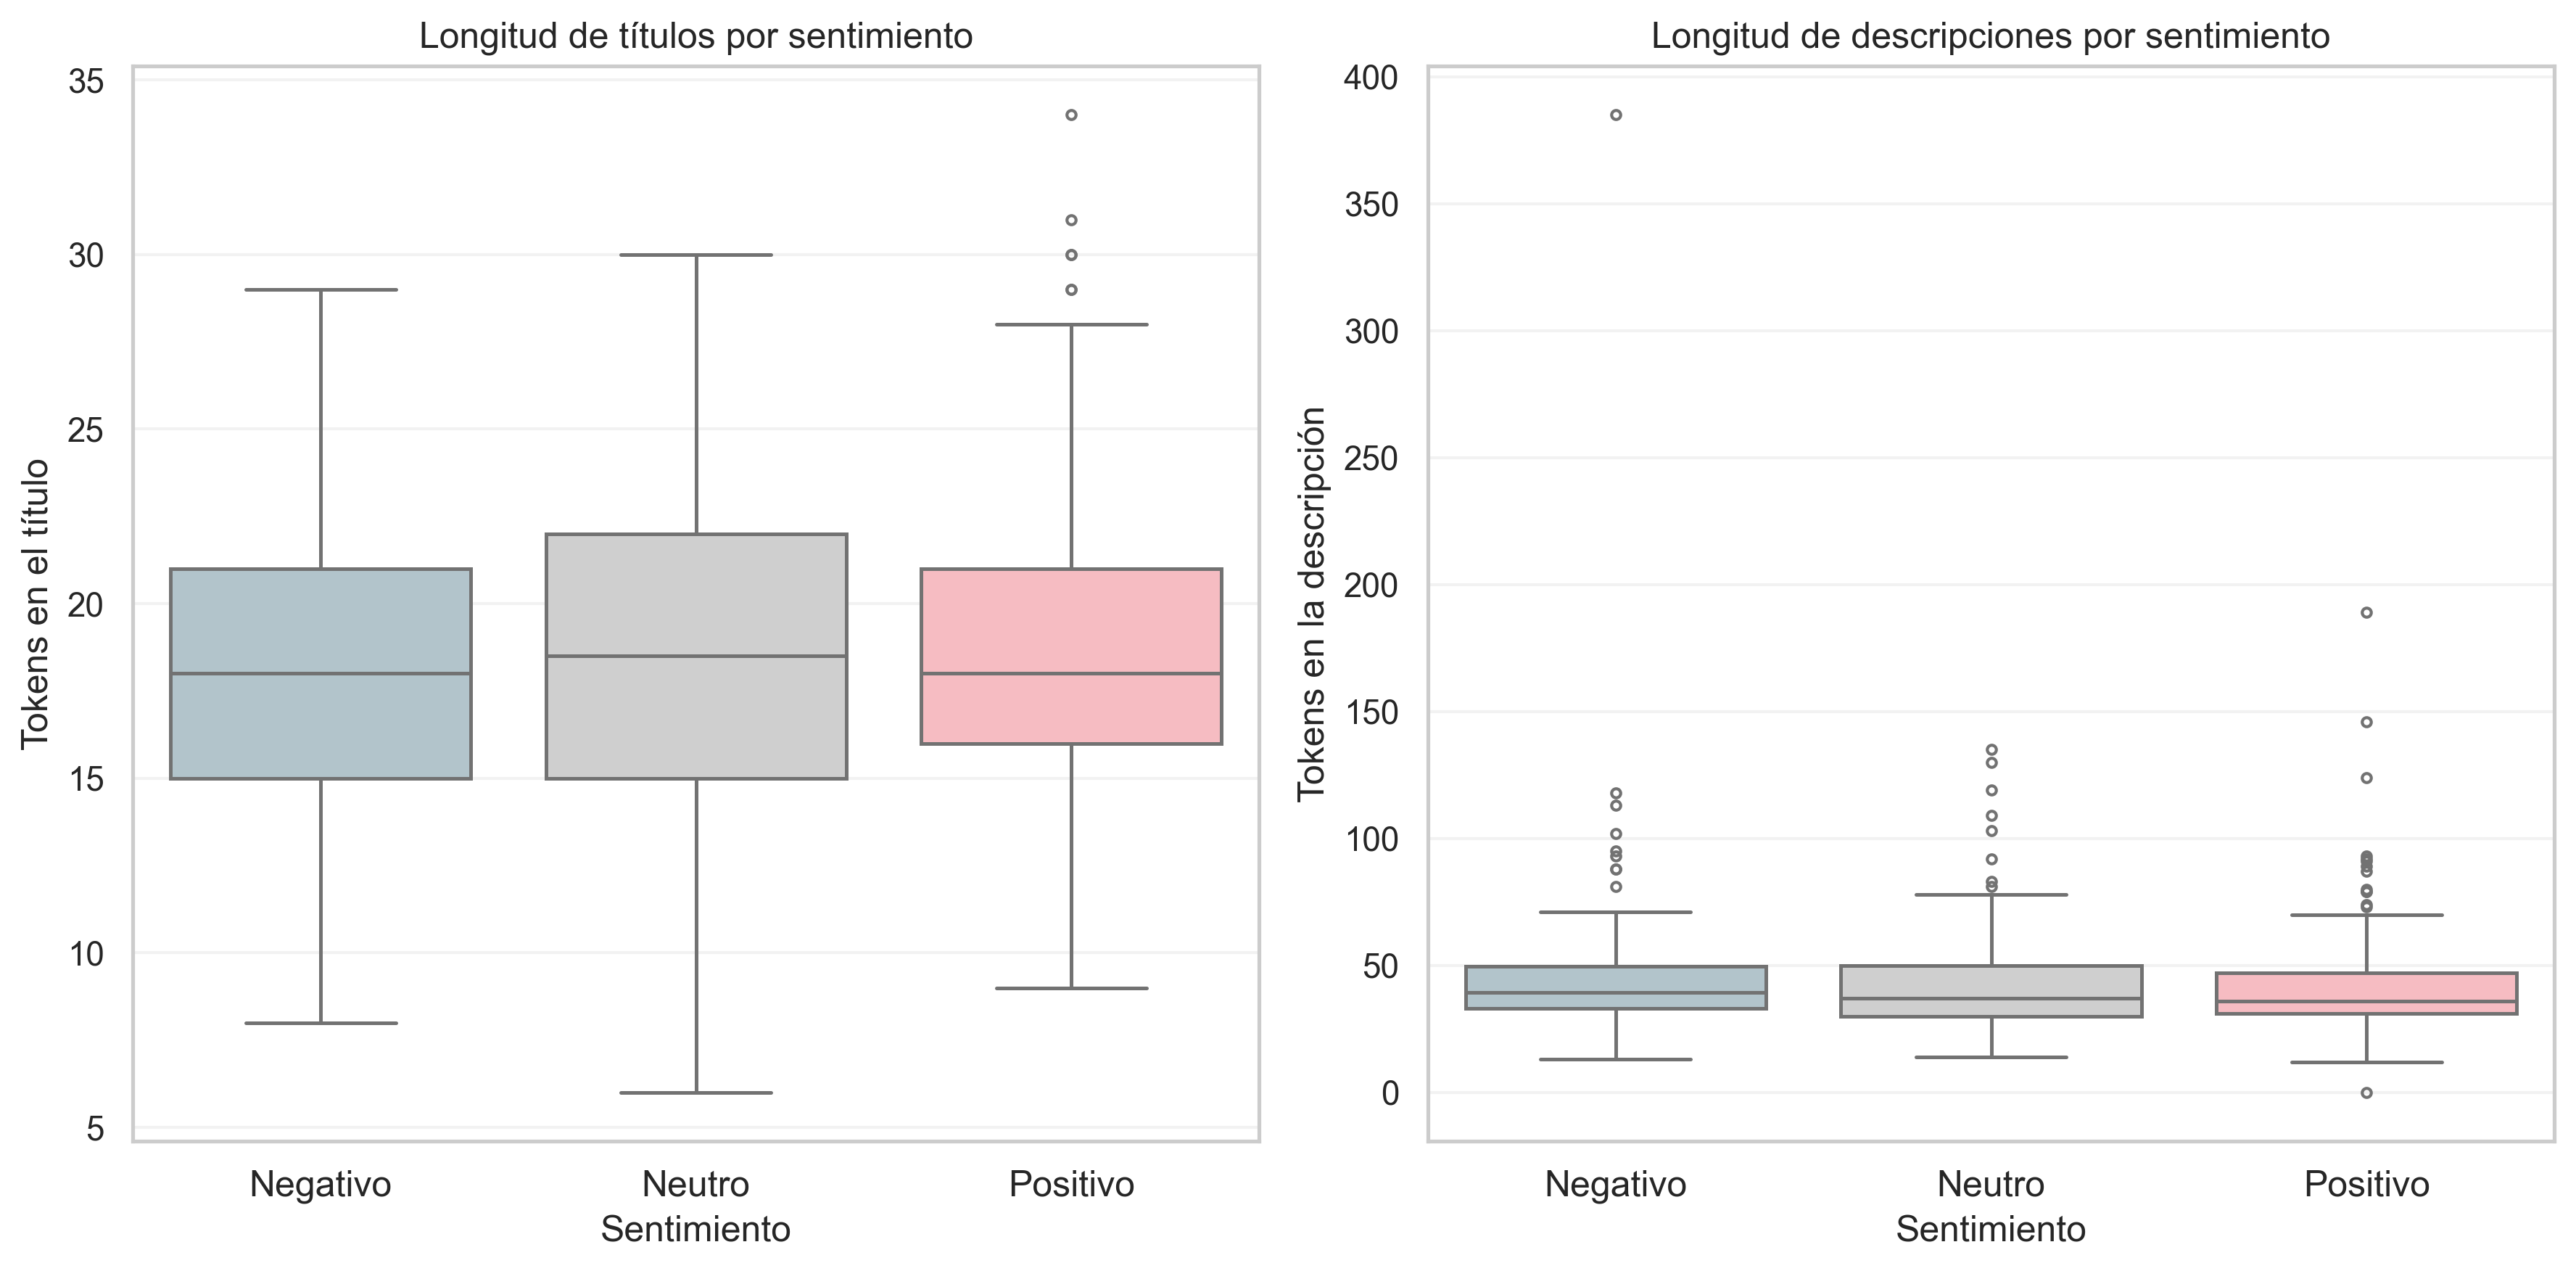

In [34]:
# Longitud por etiqueta de sentimiento (boxplots)
# Nota: en Seaborn 0.13.x, usar `palette` sin `hue` genera FutureWarning. Para mantener colores por clase
# sin warnings, asignamos `hue=x`, `dodge=False` y `legend=False`. También fijamos ticks antes de labels.

# Preparación: sentimiento numérico + filas completas
_plot = df.copy()
_plot["sentimiento"] = pd.to_numeric(_plot["sentimiento"], errors="coerce")
_plot = _plot.dropna(subset=["sentimiento", "n_tokens_titulo", "n_tokens_descripcion"])
_plot["sentimiento"] = _plot["sentimiento"].astype(int)

# Orden/paleta solo con clases presentes (evita cajas vacías)
orden_preferido = [-1, 0, 1]
order = [v for v in orden_preferido if v in set(_plot["sentimiento"].unique())]
labels_legibles = [{-1: "Negativo", 0: "Neutro", 1: "Positivo"}[i] for i in order]
palette_box = {i: {-1: "#AEC6CF", 0: "#CFCFCF", 1: "#FFB3BA"}[i] for i in order}

# Gráfico (dos paneles con configuración compartida)
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 6), dpi=300)

for ax, ycol, titulo, ylabel in [
    (axes[0], "n_tokens_titulo", "Longitud de títulos por sentimiento", "Tokens en el título"),
    (axes[1], "n_tokens_descripcion", "Longitud de descripciones por sentimiento", "Tokens en la descripción"),
]:
    sns.boxplot(
        data=_plot,
        x="sentimiento",
        y=ycol,
        order=order,
        hue="sentimiento",
        hue_order=order,
        palette=palette_box,
        dodge=False,
        linewidth=1.2,
        fliersize=3,
        legend=False,
        ax=ax,
    )
    ax.set(title=titulo, xlabel="Sentimiento", ylabel=ylabel)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(labels_legibles)
    ax.tick_params(axis="x", labelsize=12)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


### 4. Ejemplos de noticias por clase

Para complementar las métricas agregadas, es útil ver algunos ejemplos cualitativos por clase de sentimiento. Esto ayuda a validar:

- Si la etiqueta asignada es coherente con el tono del texto.
- Si el tipo de noticias corresponde a lo que esperamos que el modelo aprenda.

A continuación se muestran algunas noticias de ejemplo para cada etiqueta.

In [35]:
# Mostrar algunos ejemplos por clase

for etiqueta, nombre in [(-1, "negativo"), (0, "neutro"), (1, "positivo")]:
    print("=" * 60)
    print(f"Ejemplos de noticias con sentimiento {nombre} ({etiqueta})")
    ejemplos = df[df["sentimiento"] == etiqueta].head(3)
    display(ejemplos[["sentimiento", "titulo", "descripcion", "url"]])

Ejemplos de noticias con sentimiento negativo (-1)


,sentimiento,titulo,descripcion,url
0,-1,Actividad industrial cayó 1.1% en enero y romp...,Se observaron retrocesos en todos los componen...,https://www.eleconomista.com.mx/empresas/activ...
1,-1,Bolsa mexicana retrocede; acciones de mineras ...,Los índices accionarios locales bajan por segu...,https://www.eleconomista.com.mx/mercados/bolsa...
6,-1,Peso mexicano retrocede frente al dólar tras a...,El peso se depreció en un mercado nerviosos de...,https://www.eleconomista.com.mx/mercados/preci...


Ejemplos de noticias con sentimiento neutro (0)


,sentimiento,titulo,descripcion,url
5,0,STPS se compromete a revisar las cargas fiscal...,Durante la inauguración del LXX Consejo Nacion...,https://www.eleconomista.com.mx/empresas/stps-...
7,0,Secretaría Anticorrupción y Buen Gobierno reve...,La Secretaría Anticorrupción y Buen Gobierno p...,https://www.eleconomista.com.mx/politica/secre...
10,0,"Seguridad, certeza jurídica y energía, necesar...","El presidente nacional de la Coparmex, Juan Jo...",https://www.eleconomista.com.mx/estados/seguri...


Ejemplos de noticias con sentimiento positivo (1)


,sentimiento,titulo,descripcion,url
2,1,Peso mexicano recupera terreno frente al dólar,El peso recupera terreno después de una jornad...,https://www.eleconomista.com.mx/videos/peso-me...
3,1,Ecuador anuncia millonaria inversión de Améric...,El Gobierno de ⁠Ecuador dijo este viernes que ...,https://www.eleconomista.com.mx/empresas/ecuad...
4,1,Expectativas de empleo en México aumentan prev...,El Mundial 2026 será un catalizador para el em...,https://www.eleconomista.com.mx/videos/expecta...


### 5. Unión de título y descripción (texto_input)

Para uso en modelos de clasificación (p. ej. BERT) suele ser útil tener un único campo de texto por noticia. Aquí se crea la columna **`texto_input`** que concatena `titulo` y `descripcion` separados por un espacio. El archivo `noticias_etiquetadas.csv` no se modifica, la nueva columna existe solo en el DataFrame del notebook.

In [36]:
# Unir titulo + descripcion (sin modificar el CSV original)
df["texto_input"] = (df["titulo"].fillna("") + " " + df["descripcion"].fillna("")).str.strip()

# Mostrar primeras filas con la nueva columna
display(df[["sentimiento", "titulo", "descripcion", "texto_input"]].head())

,sentimiento,titulo,descripcion,texto_input
0,-1,Actividad industrial cayó 1.1% en enero y romp...,Se observaron retrocesos en todos los componen...,Actividad industrial cayó 1.1% en enero y romp...
1,-1,Bolsa mexicana retrocede; acciones de mineras ...,Los índices accionarios locales bajan por segu...,Bolsa mexicana retrocede; acciones de mineras ...
2,1,Peso mexicano recupera terreno frente al dólar,El peso recupera terreno después de una jornad...,Peso mexicano recupera terreno frente al dólar...
3,1,Ecuador anuncia millonaria inversión de Améric...,El Gobierno de ⁠Ecuador dijo este viernes que ...,Ecuador anuncia millonaria inversión de Améric...
4,1,Expectativas de empleo en México aumentan prev...,El Mundial 2026 será un catalizador para el em...,Expectativas de empleo en México aumentan prev...


### 6. Tokenización y recorte a 80 tokens

Se guarda una **copia** de `texto_input` en la columna **`texto_input_original`** para poder probar después con distinto número de tokens sin perder el texto completo. A continuación se tokeniza cada texto con un tokenizer tipo BERT (español o multilingüe), se recorta a **80 tokens** y se decodifica de nuevo a texto en la columna **`texto_input_80tokens`**. Si más adelante quieres usar otro máximo (p. ej. 128 o 256), puedes reutilizar `texto_input_original` y cambiar la constante `MAX_TOKENS`.

In [37]:
# Guardar copia del texto completo (útil si luego cambias MAX_TOKENS)
df["texto_input_original"] = df["texto_input"].copy()

# Tokenizar y recortar a 80 tokens con un tokenizer BERT en español
from transformers import AutoTokenizer

MAX_TOKENS = 80
tokenizer = AutoTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")


def _truncar_80(t):
    """Trunca `t` a MAX_TOKENS y lo devuelve como texto (string)."""
    t = "" if pd.isna(t) else str(t).strip()
    if not t:
        return ""
    ids = tokenizer(t, truncation=True, max_length=MAX_TOKENS)["input_ids"]
    return tokenizer.decode(ids, skip_special_tokens=True)


df["texto_input_80tokens"] = df["texto_input"].apply(_truncar_80)

# Verificación: contar tokens por fila (opcional)
df["n_tokens_80"] = df["texto_input_80tokens"].map(
    lambda t: len(tokenizer.encode(t, add_special_tokens=True)) if str(t).strip() else 0
)
print("Tokens por fila (máx 80):")
print(df["n_tokens_80"].describe())

display(df[["sentimiento", "texto_input_original", "texto_input_80tokens", "n_tokens_80"]].head())


Tokens por fila (máx 80):
count    517.000000
mean      56.294004
std       13.675029
min       23.000000
25%       47.000000
50%       54.000000
75%       66.000000
max       80.000000
Name: n_tokens_80, dtype: float64


,sentimiento,texto_input_original,texto_input_80tokens,n_tokens_80
0,-1,Actividad industrial cayó 1.1% en enero y romp...,Actividad industrial cayó 1. 1 % en enero y ro...,58
1,-1,Bolsa mexicana retrocede; acciones de mineras ...,Bolsa mexicana retrocede ; acciones de mineras...,45
2,1,Peso mexicano recupera terreno frente al dólar...,Peso mexicano recupera terreno frente al dólar...,31
3,1,Ecuador anuncia millonaria inversión de Améric...,Ecuador anuncia millonaria inversión de Améric...,41
4,1,Expectativas de empleo en México aumentan prev...,Expectativas de empleo en México aumentan prev...,56


In [38]:
df["sentimiento"].isna().sum()
df["sentimiento"].dtype

dtype('int64')

### 7. Prueba de sentimiento con *finance-sentiment-es-base*

Se usa el modelo [**bardsai/finance-sentiment-es-base**](https://huggingface.co/bardsai/finance-sentiment-es-base) de Hugging Face: BERT en español para noticias financieras, entrenado sobre Financial PhraseBank. Devuelve tres etiquetas: **positive**, **negative**, **neutral**, y un score de confianza. Aquí se aplica sobre `texto_input_80tokens` para obtener la predicción por noticia.

In [39]:
from transformers import pipeline

nlp = pipeline("sentiment-analysis", model="bardsai/finance-sentiment-es-base")
preds = nlp(df["texto_input_80tokens"].tolist())
df["pred_label"] = [p["label"] for p in preds]
df["pred_score"] = [p["score"] for p in preds]
df["pred_sentimiento"] = df["pred_label"].map({"negative": -1, "neutral": 0, "positive": 1})

# sentimiento puede venir como float64 con NaN; .astype(int) falla. Solo comparamos filas válidas.
sent = pd.to_numeric(df["sentimiento"], errors="coerce")
pred = pd.to_numeric(df["pred_sentimiento"], errors="coerce")
valid = sent.notna() & pred.notna()
if valid.sum() == 0:
    print("Exactitud vs. etiqueta real: n/d (sin filas con etiqueta real y predicción válidas)")
else:
    aciertos = sent[valid].astype(int) == pred[valid].astype(int)
    print(
        "Exactitud vs. etiqueta real:",
        round(float(aciertos.mean()), 3),
        f"(comparadas {int(valid.sum())} de {len(df)} filas)",
    )
display(df[["sentimiento", "pred_label", "pred_score", "texto_input_80tokens"]].head(10))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Exactitud vs. etiqueta real: 0.652 (comparadas 517 de 517 filas)


,sentimiento,pred_label,pred_score,texto_input_80tokens
0,-1,negative,0.999894,Actividad industrial cayó 1. 1 % en enero y ro...
1,-1,negative,0.999894,Bolsa mexicana retrocede ; acciones de mineras...
2,1,positive,0.999920,Peso mexicano recupera terreno frente al dólar...
3,1,neutral,0.999950,Ecuador anuncia millonaria inversión de Améric...
4,1,positive,0.999944,Expectativas de empleo en México aumentan prev...
5,0,neutral,0.999982,STPS se compromete a revisar las cargas fiscal...
6,-1,negative,0.999813,Peso mexicano retrocede frente al dólar tras a...
7,0,neutral,0.999984,Secretaría Anticorrupción y Buen Gobierno reve...
8,1,positive,0.999943,"Planta de BYD en Brasil consigue 100, 000 pedi..."
9,-1,negative,0.999895,Bolsa mexicana retrocede ; las mineras y Orbia...


In [40]:
from transformers import pipeline

nlp = pipeline("sentiment-analysis", model="bardsai/finance-sentiment-es-base")

preds = nlp(df["texto_input_80tokens"].tolist())

df["pred_label"] = [p["label"] for p in preds]
df["pred_score"] = [p["score"] for p in preds]
df["pred_sentimiento"] = df["pred_label"].map({
    "negative": -1,
    "neutral": 0,
    "positive": 1
})

# Evaluación (sentimiento como float64 / con NaN: evitar .astype(int) directo sobre toda la columna)
sent = pd.to_numeric(df["sentimiento"], errors="coerce")
pred = pd.to_numeric(df["pred_sentimiento"], errors="coerce")
valid = sent.notna() & pred.notna()
if valid.sum() == 0:
    print("Exactitud vs. etiqueta real: n/d (sin filas con etiqueta real y predicción válidas)")
else:
    aciertos = sent[valid].astype(int) == pred[valid].astype(int)
    print(
        "Exactitud vs. etiqueta real:",
        round(float(aciertos.mean()), 3),
        f"(comparadas {int(valid.sum())} de {len(df)} filas)",
    )

display(df[["sentimiento", "pred_label", "pred_score", "texto_input_80tokens"]].head(10))

# Guardar CSV
#df_output = df[["pred_sentimiento", "texto_input_80tokens"]].copy()
#df_output.to_csv("predicciones_bardsai.csv", index=False, encoding="utf-8")
#print("Archivo 'predicciones_bardsai.csv' guardado correctamente.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Exactitud vs. etiqueta real: 0.652 (comparadas 517 de 517 filas)


,sentimiento,pred_label,pred_score,texto_input_80tokens
0,-1,negative,0.999894,Actividad industrial cayó 1. 1 % en enero y ro...
1,-1,negative,0.999894,Bolsa mexicana retrocede ; acciones de mineras...
2,1,positive,0.999920,Peso mexicano recupera terreno frente al dólar...
3,1,neutral,0.999950,Ecuador anuncia millonaria inversión de Améric...
4,1,positive,0.999944,Expectativas de empleo en México aumentan prev...
5,0,neutral,0.999982,STPS se compromete a revisar las cargas fiscal...
6,-1,negative,0.999813,Peso mexicano retrocede frente al dólar tras a...
7,0,neutral,0.999984,Secretaría Anticorrupción y Buen Gobierno reve...
8,1,positive,0.999943,"Planta de BYD en Brasil consigue 100, 000 pedi..."
9,-1,negative,0.999895,Bolsa mexicana retrocede ; las mineras y Orbia...


### 8. Sentimiento con BERT usando título+descripción completos

Ahora reutilizamos el mismo modelo `finance-sentiment-es-base`, pero aplicándolo a `texto_input_original` (título + descripción **sin recorte a 80 tokens**) para comparar el desempeño cuando se usa el texto completo.

In [41]:
# Inferencia del modelo usando el texto completo (título + descripción sin recorte)
preds_full = nlp(df["texto_input_original"].tolist())

# Guardar etiqueta, score de confianza y versión numérica (-1, 0, 1)
df["pred_label_full"] = [p["label"] for p in preds_full]
df["pred_score_full"] = [p["score"] for p in preds_full]
df["pred_sent_full"] = df["pred_label_full"].map({"negative": -1, "neutral": 0, "positive": 1})

# Evaluar exactitud vs etiqueta real (solo filas con etiqueta real y predicción válidas)
sent = pd.to_numeric(df["sentimiento"], errors="coerce")
pred = pd.to_numeric(df["pred_sent_full"], errors="coerce")
valid = sent.notna() & pred.notna()
if valid.sum() == 0:
    print("Exactitud con texto completo: n/d (sin filas comparables)")
else:
    aciertos = sent[valid].astype(int) == pred[valid].astype(int)
    print(
        "Exactitud con texto completo:",
        round(float(aciertos.mean()), 3),
        f"(comparadas {int(valid.sum())} de {len(df)} filas)",
    )

# Vista rápida de resultados y texto completo
display(df[["sentimiento", "pred_label_full", "pred_score_full", "texto_input_original"]].head(10))


Exactitud con texto completo: 0.646 (comparadas 517 de 517 filas)


,sentimiento,pred_label_full,pred_score_full,texto_input_original
0,-1,negative,0.999894,Actividad industrial cayó 1.1% en enero y romp...
1,-1,negative,0.999894,Bolsa mexicana retrocede; acciones de mineras ...
2,1,positive,0.999920,Peso mexicano recupera terreno frente al dólar...
3,1,neutral,0.999950,Ecuador anuncia millonaria inversión de Améric...
4,1,positive,0.999944,Expectativas de empleo en México aumentan prev...
5,0,neutral,0.999982,STPS se compromete a revisar las cargas fiscal...
6,-1,negative,0.999813,Peso mexicano retrocede frente al dólar tras a...
7,0,neutral,0.999984,Secretaría Anticorrupción y Buen Gobierno reve...
8,1,positive,0.999943,"Planta de BYD en Brasil consigue 100,000 pedid..."
9,-1,negative,0.999895,Bolsa mexicana retrocede; las mineras y Orbia ...


### 9. Sentimiento con BERT usando solo el título

Por último, evaluamos el modelo `finance-sentiment-es-base` cuando el `input_text` es únicamente el **título** de la noticia, para ver cuánto aporta el cuerpo (descripción) frente al titular.

In [42]:
# Inferencia del modelo usando solo el título (baseline para comparar vs. 80 tokens / texto completo)
preds_title = nlp(df["titulo"].fillna("").tolist())

# Guardar etiqueta, score de confianza y versión numérica (-1, 0, 1)
df["pred_label_title"] = [p["label"] for p in preds_title]
df["pred_score_title"] = [p["score"] for p in preds_title]
df["pred_sent_title"] = df["pred_label_title"].map({"negative": -1, "neutral": 0, "positive": 1})

# Evaluar exactitud vs etiqueta real (solo filas con etiqueta real y predicción válidas)
sent = pd.to_numeric(df["sentimiento"], errors="coerce")
pred = pd.to_numeric(df["pred_sent_title"], errors="coerce")
valid = sent.notna() & pred.notna()
if valid.sum() == 0:
    print("Exactitud usando solo el título: n/d (sin filas comparables)")
else:
    aciertos = sent[valid].astype(int) == pred[valid].astype(int)
    print(
        "Exactitud usando solo el título:",
        round(float(aciertos.mean()), 3),
        f"(comparadas {int(valid.sum())} de {len(df)} filas)",
    )

# Vista rápida: etiqueta real, predicción y título
display(df[["sentimiento", "pred_label_title", "pred_score_title", "titulo"]].head(10))


Exactitud usando solo el título: 0.534 (comparadas 517 de 517 filas)


,sentimiento,pred_label_title,pred_score_title,titulo
0,-1,negative,0.999893,Actividad industrial cayó 1.1% en enero y romp...
1,-1,negative,0.999653,Bolsa mexicana retrocede; acciones de mineras ...
2,1,positive,0.724702,Peso mexicano recupera terreno frente al dólar
3,1,neutral,0.999964,Ecuador anuncia millonaria inversión de Améric...
4,1,positive,0.999943,Expectativas de empleo en México aumentan prev...
5,0,neutral,0.999981,STPS se compromete a revisar las cargas fiscal...
6,-1,negative,0.999239,Peso mexicano retrocede frente al dólar tras a...
7,0,neutral,0.999983,Secretaría Anticorrupción y Buen Gobierno reve...
8,1,positive,0.999936,"Planta de BYD en Brasil consigue 100,000 pedid..."
9,-1,negative,0.998472,Bolsa mexicana retrocede; las mineras y Orbia ...


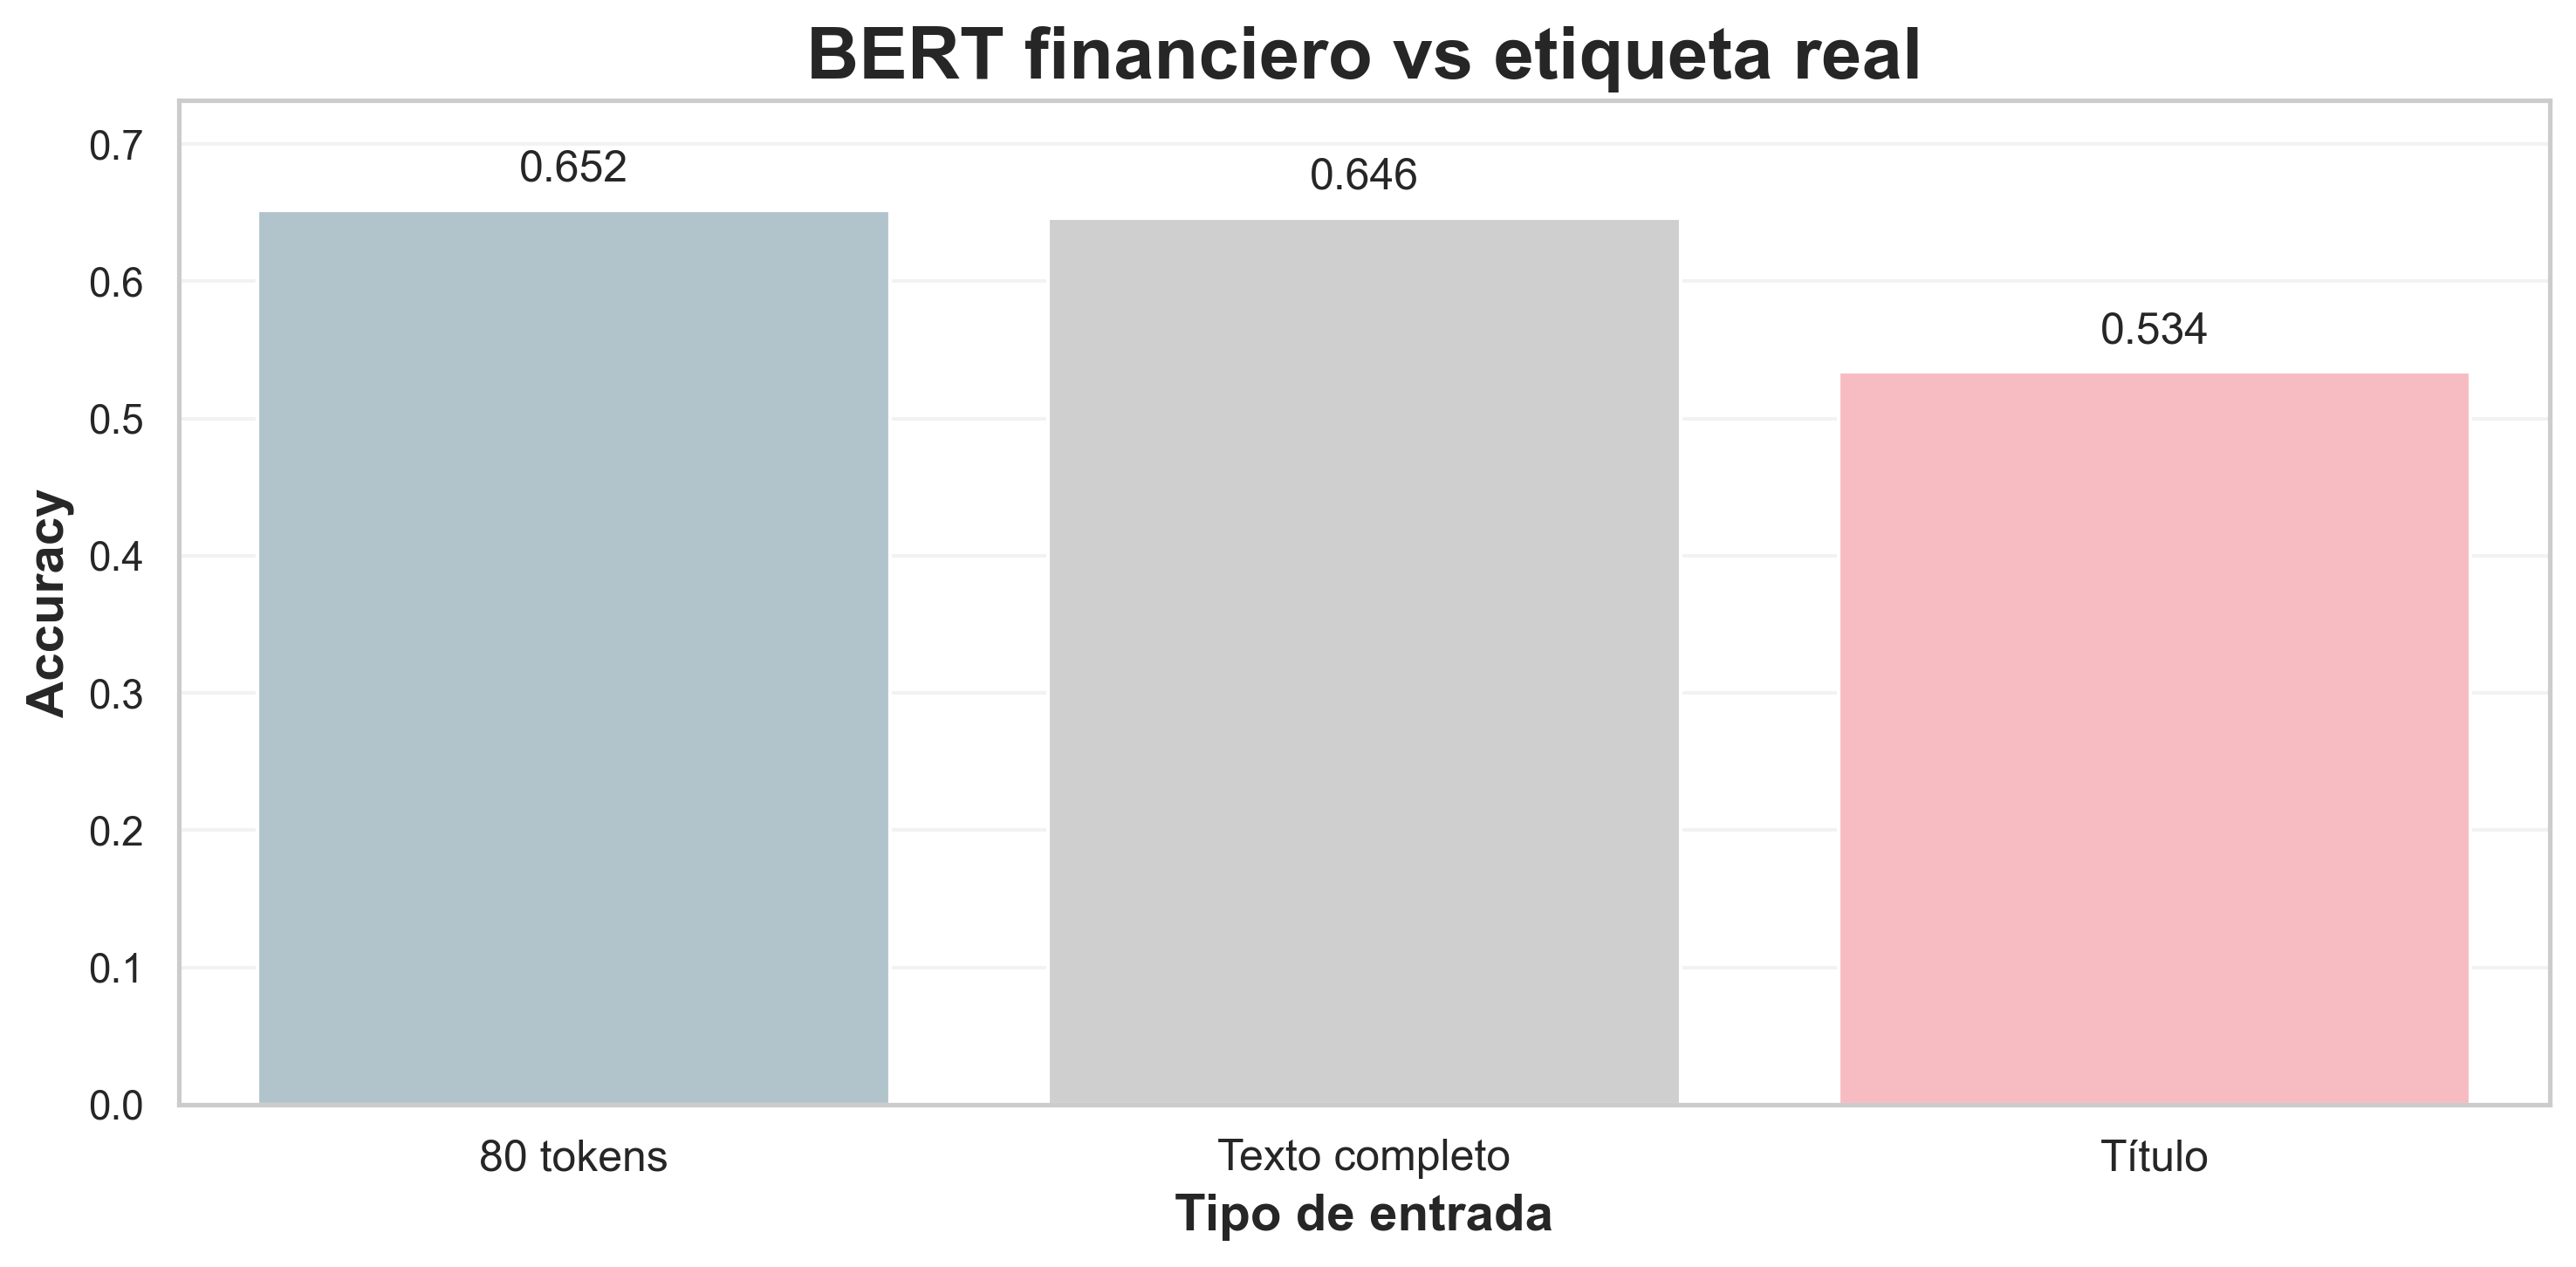

In [43]:
# Comparativo de exactitud (predicción vs etiqueta real)
# Objetivo: comparar la accuracy del modelo según el tipo de texto usado (80 tokens / texto completo / solo título).

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Función auxiliar: accuracy solo en filas con etiqueta real y predicción válidas
sent = pd.to_numeric(df["sentimiento"], errors="coerce")

def _acc(col):
    if col not in df.columns:
        return None
    pred = pd.to_numeric(df[col], errors="coerce")
    m = sent.notna() & pred.notna()
    return None if int(m.sum()) == 0 else float((sent[m].astype(int) == pred[m].astype(int)).mean())

# Construir tabla de comparación con las columnas ya generadas en el notebook
pares = [("80 tokens", "pred_sentimiento"), ("Texto completo", "pred_sent_full"), ("Título", "pred_sent_title")]
df_cmp = pd.DataFrame([{"input": n, "accuracy": a} for n, c in pares if (a := _acc(c)) is not None])
if df_cmp.empty:
    raise ValueError("No hay predicciones en df. Ejecuta antes las celdas que crean pred_sentimiento/pred_sent_full/pred_sent_title.")

# Gráfica de barras (hue=x para usar paleta sin warnings)
sns.set_style("whitegrid")
palette = {"80 tokens": "#AEC6CF", "Texto completo": "#CFCFCF", "Título": "#FFB3BA"}

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
sns.barplot(
    data=df_cmp,
    x="input",
    y="accuracy",
    hue="input",
    palette=palette,
    dodge=False,
    legend=False,
    ax=ax,
)

ax.set(title="BERT financiero vs etiqueta real", xlabel="Tipo de entrada", ylabel="Accuracy")
ax.set_title("BERT financiero vs etiqueta real", fontsize=20, fontweight="bold")
ax.set_xlabel("Tipo de entrada", fontsize=14, fontweight="bold")
ax.set_ylabel("Accuracy", fontsize=14, fontweight="bold")
ax.tick_params(axis="x", labelsize=12)
ax.grid(axis="y", alpha=0.25)

# Etiquetas numéricas encima de cada barra + ajuste de escala
y_max = float(df_cmp["accuracy"].max())
y_upper = min(1.0, y_max + 0.08)
ax.set_ylim(0.0, y_upper)
off = y_upper * 0.02
for i, v in enumerate(df_cmp["accuracy"].values):
    ax.text(i, v + off, f"{v:.3f}", ha="center", va="bottom", fontsize=12)

plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import classification_report, f1_score
from transformers import pipeline

import pandas as pd

# F1 (sin CV): comparar 80 tokens vs solo título (mismo modelo, distintas entradas)
label_map = {"negative": -1, "neutral": 0, "positive": 1}
labels = [-1, 0, 1]

# Usar solo filas con etiqueta real válida (evita NaN al evaluar)
_mask = pd.to_numeric(df["sentimiento"], errors="coerce").notna()
if int(_mask.sum()) < len(df):
    print(f"[F1] Se excluyen {len(df) - int(_mask.sum())} filas sin etiqueta real (NaN).\n")
df_f1 = df.loc[_mask].reset_index(drop=True)
y_true = pd.to_numeric(df_f1["sentimiento"], errors="coerce").astype(int).values

# Pipeline de sentimiento (BERT financiero)
nlp_f1 = pipeline("sentiment-analysis", model="bardsai/finance-sentiment-es-base")


def _eval(textos, etiqueta):
    """Predice y muestra macro-F1 + reporte por clase para un tipo de entrada."""
    y_pred = [label_map[p["label"]] for p in nlp_f1([str(t or "") for t in textos])]
    macro = f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    print(f"F1 (macro) - {etiqueta}:", round(macro, 3))
    print(f"\nReporte por clase - {etiqueta}:")
    print(classification_report(y_true, y_pred, labels=labels, zero_division=0, digits=3))


# Evaluaciones
_eval(df_f1["texto_input_80tokens"].fillna("").astype(str).tolist(), "texto_input_80tokens")
_eval(df_f1["titulo"].fillna("").astype(str).tolist(), "solo título")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

F1 (macro) - texto_input_80tokens: 0.664

Reporte por clase - texto_input_80tokens:
              precision    recall  f1-score   support

          -1      0.861     0.649     0.740       134
           0      0.561     0.709     0.626       182
           1      0.651     0.602     0.625       201

    accuracy                          0.652       517
   macro avg      0.691     0.653     0.664       517
weighted avg      0.674     0.652     0.655       517

F1 (macro) - solo título: 0.534

Reporte por clase - solo título:
              precision    recall  f1-score   support

          -1      0.877     0.425     0.573       134
           0      0.439     0.786     0.563       182
           1      0.603     0.378     0.465       201

    accuracy                          0.534       517
   macro avg      0.640     0.530     0.534       517
weighted avg      0.616     0.534     0.527       517



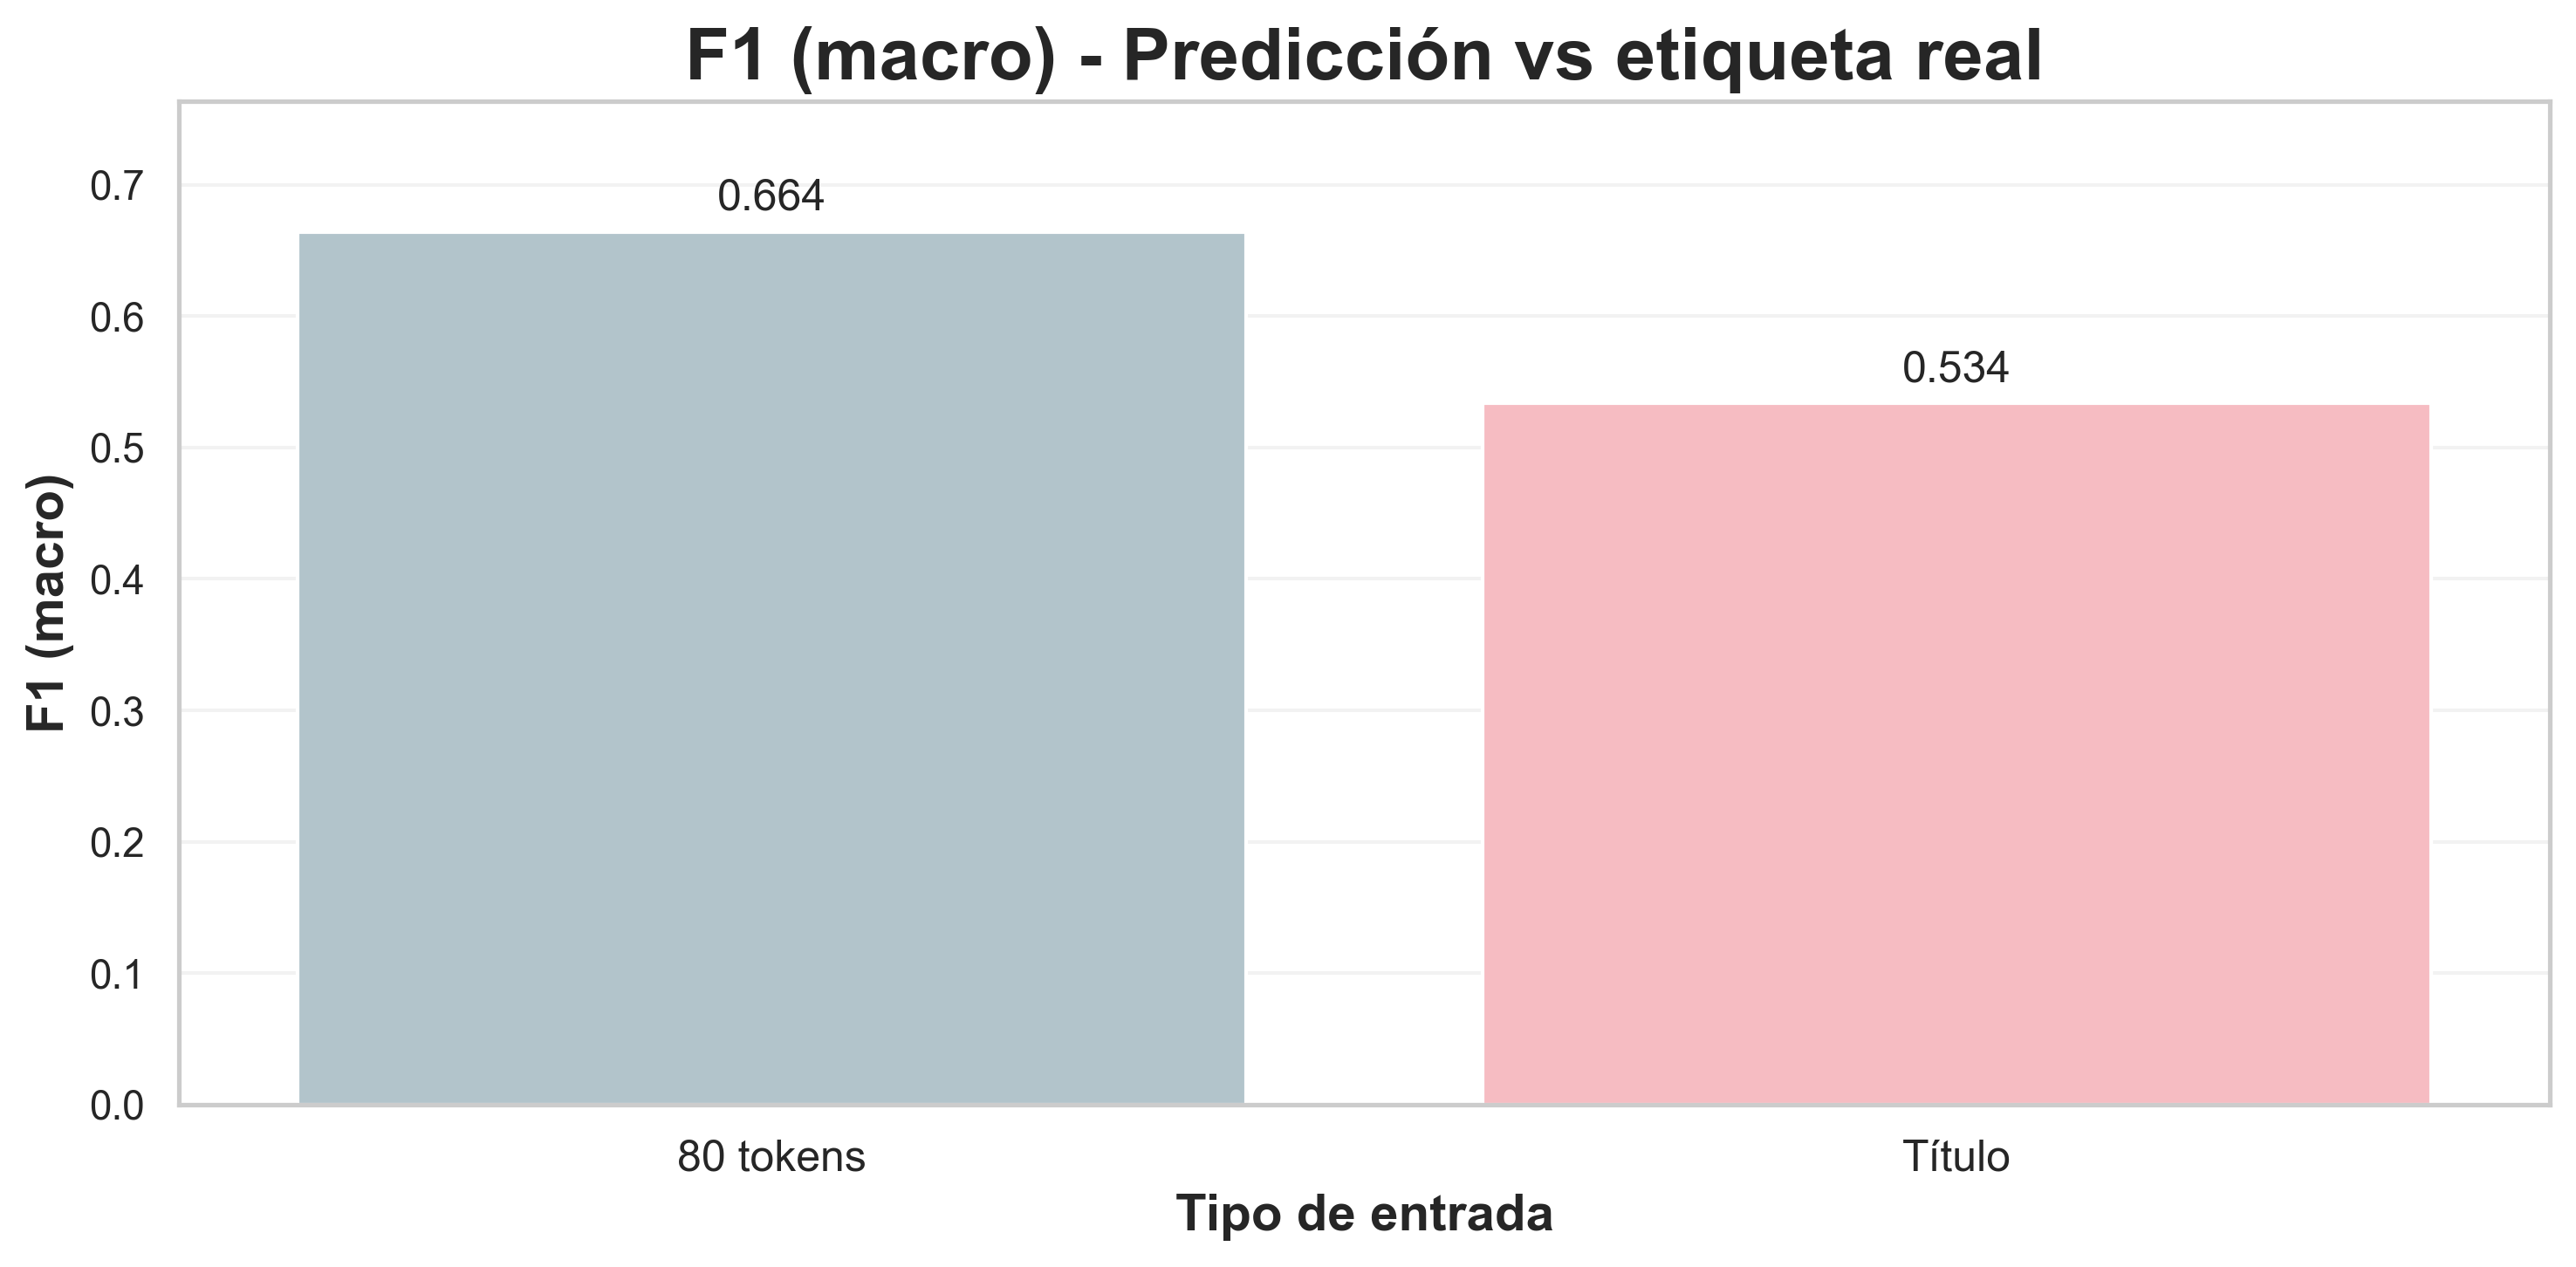

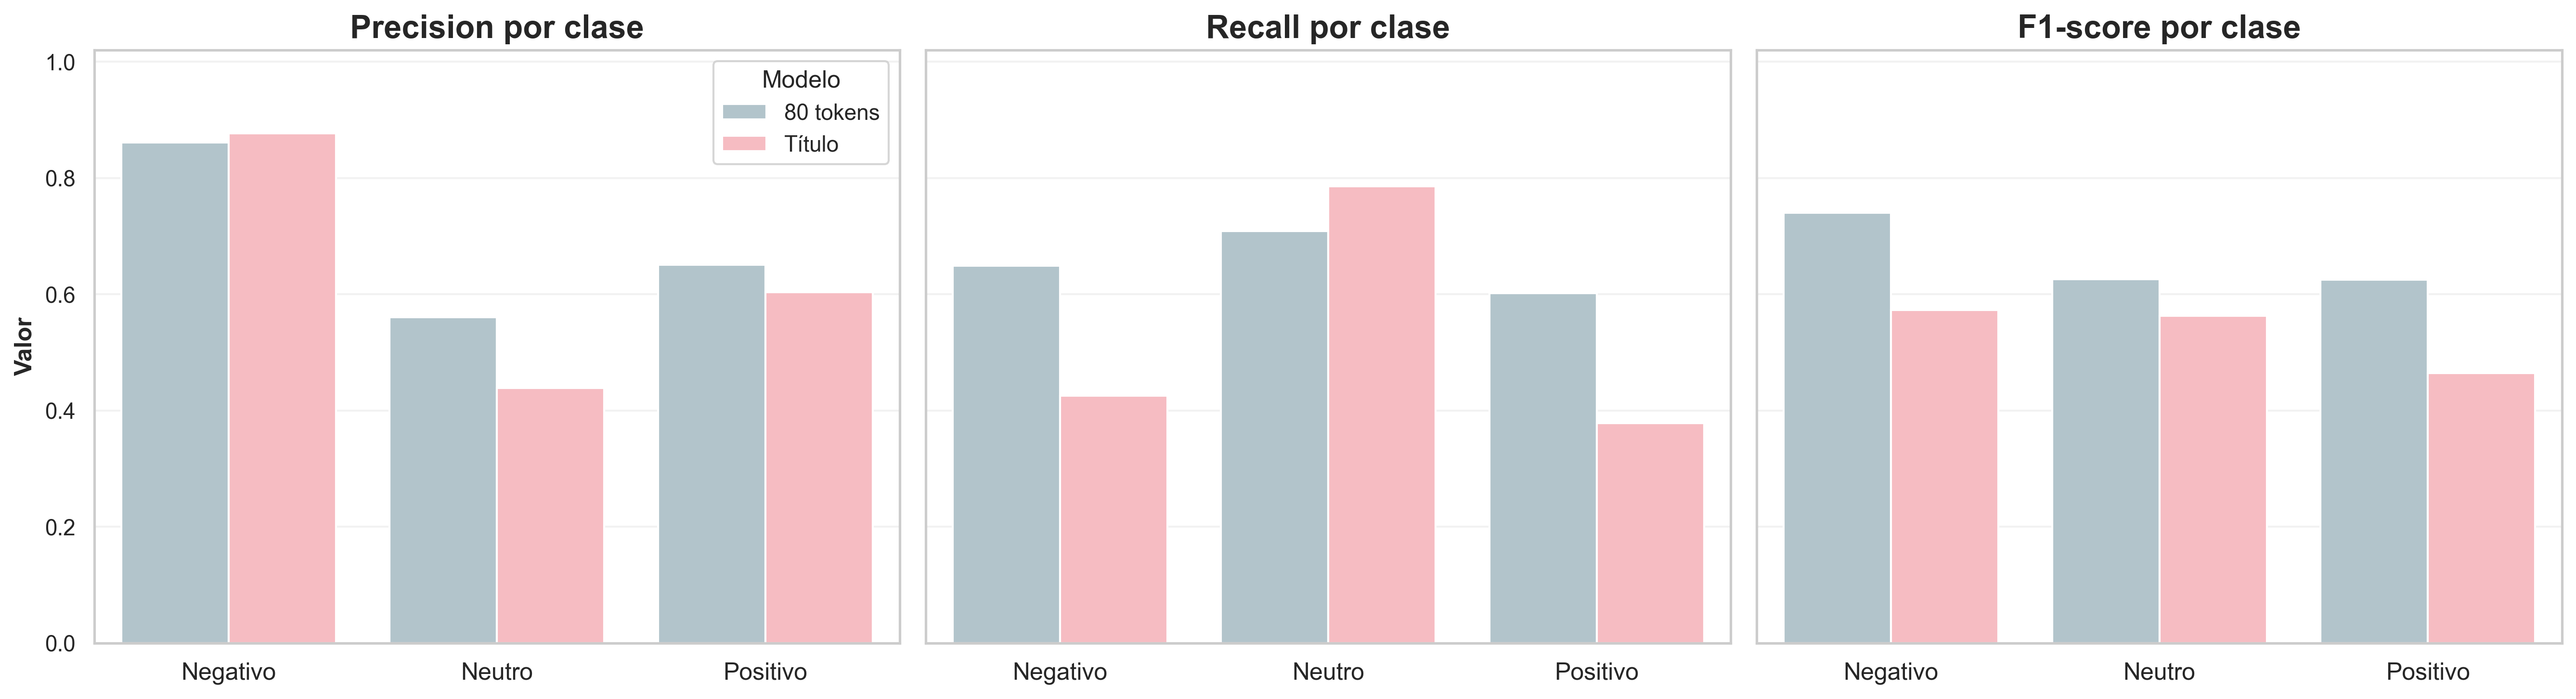

In [45]:
# Visualizaciones (sin CV)
# Este bloque continúa el paso anterior: usa `y_true`, `df_f1` y `nlp_f1` para comparar 80 tokens vs título.

sns.set_style("whitegrid")

# Predicciones por variante de entrada
_variantes = {
    "80 tokens": df_f1["texto_input_80tokens"].fillna("").astype(str).tolist(),
    "Título": df_f1["titulo"].fillna("").astype(str).tolist(),
}

def _y_pred(textos):
    return [label_map[p["label"]] for p in nlp_f1(textos)]

preds = {k: _y_pred(v) for k, v in _variantes.items()}

# Macro-F1 (resumen) + gráfica
macro = {k: f1_score(y_true, y, labels=labels, average="macro", zero_division=0) for k, y in preds.items()}
df_macro = pd.DataFrame({"modelo": list(macro), "macro_f1": list(macro.values())})

palette = {"80 tokens": "#AEC6CF", "Título": "#FFB3BA"}
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
sns.barplot(data=df_macro, x="modelo", y="macro_f1", hue="modelo", palette=palette, dodge=False, legend=False, ax=ax)
ax.set_title("F1 (macro) - Predicción vs etiqueta real", fontsize=20, fontweight="bold")
ax.set_xlabel("Tipo de entrada", fontsize=14, fontweight="bold")
ax.set_ylabel("F1 (macro)", fontsize=14, fontweight="bold")
ax.tick_params(axis="x", labelsize=12)
ax.grid(axis="y", alpha=0.25)
ax.set_ylim(0, max(df_macro["macro_f1"].max() * 1.15, 0.1))
for i, v in enumerate(df_macro["macro_f1"].values):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", va="bottom", fontsize=12)
plt.tight_layout()
plt.show()

# Métricas por clase (precision/recall/f1) a partir de classification_report
class_names = {-1: "Negativo", 0: "Neutro", 1: "Positivo"}
class_order = [class_names[i] for i in labels]

rows = []
for modelo, y in preds.items():
    rep = classification_report(y_true, y, labels=labels, zero_division=0, digits=3, output_dict=True)
    rows += [
        {"clase": class_names[l], "modelo": modelo, "metric": m, "valor": rep[str(l)][m]}
        for l in labels
        for m in ["precision", "recall", "f1-score"]
    ]

df_metrics = pd.DataFrame(rows)
df_metrics["clase"] = pd.Categorical(df_metrics["clase"], categories=class_order, ordered=True)

metric_titles = {"precision": "Precision por clase", "recall": "Recall por clase", "f1-score": "F1-score por clase"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=300, sharey=True)

for ax, metric in zip(axes, ["precision", "recall", "f1-score"]):
    sns.barplot(
        data=df_metrics[df_metrics["metric"] == metric],
        x="clase",
        y="valor",
        hue="modelo",
        palette=palette,
        ax=ax,
    )
    ax.set_title(metric_titles[metric], fontsize=16, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Valor" if ax is axes[0] else "", fontweight="bold")
    ax.set_ylim(0, 1.02)
    ax.tick_params(axis="x", labelsize=12)
    ax.grid(axis="y", alpha=0.25)
    if ax is not axes[0] and ax.get_legend() is not None:
        ax.get_legend().remove()

handles, labels_leg = axes[0].get_legend_handles_labels()
axes[0].legend(handles, labels_leg, title="Modelo", loc="upper right")
plt.tight_layout()
plt.show()


### 10. AUC-ROC (80 tokens vs etiqueta real)

AUC-ROC **macro** (one-vs-rest) sobre las probabilidades del modelo para las tres clases (`negative`, `neutral`, `positive`), comparadas con `sentimiento` (-1, 0, 1). Solo filas con etiqueta válida.

In [46]:
from sklearn.metrics import roc_auc_score
import numpy as np

# AUC-ROC macro (One-vs-Rest) para 3 clases: negativo (-1), neutro (0), positivo (1)
# Usar solo filas con etiqueta real válida
m = pd.to_numeric(df["sentimiento"], errors="coerce").notna()
y = pd.to_numeric(df.loc[m, "sentimiento"], errors="coerce").astype(int).values

# Obtener probabilidades del modelo para cada clase (top_k=None devuelve scores por etiqueta)
preds = nlp(df.loc[m, "texto_input_80tokens"].fillna("").astype(str).tolist(), top_k=None)

# Convertir lista de dicts a matriz P (N x 3) en el orden: negative, neutral, positive
idx = {"negative": 0, "neutral": 1, "positive": 2}
P = np.zeros((len(preds), 3))
for i, sc in enumerate(preds):
    for d in sc:
        P[i, idx[d["label"]]] = d["score"]

# Calcular AUC-ROC macro OvR
auc = roc_auc_score(y, P, average="macro", multi_class="ovr", labels=[-1, 0, 1])
print("AUC-ROC (macro OvR, 80 tokens):", round(float(auc), 3))


AUC-ROC (macro OvR, 80 tokens): 0.788


### 12. Nube de palabras

Visualización exploratoria de los términos más frecuentes en **`texto_input_80tokens`** (mismo texto que usa el modelo BERT). Complementa el análisis de longitud y sentimiento; no sustituye métricas cuantitativas.

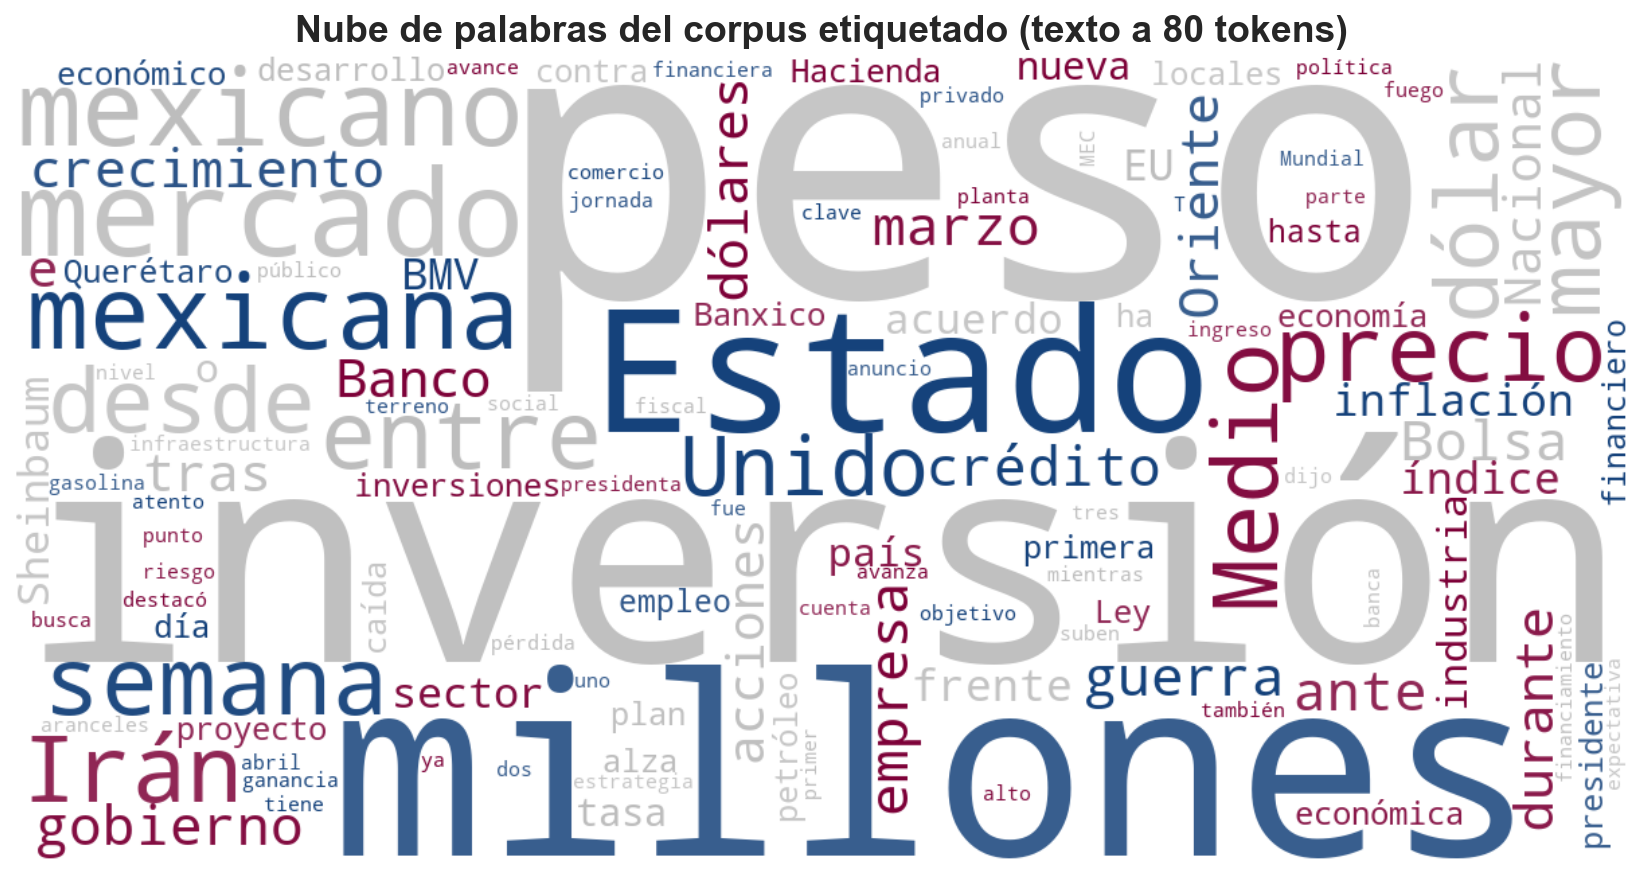

In [47]:
# Nube de palabras: términos más frecuentes en el corpus a 80 tokens
from wordcloud import WordCloud, STOPWORDS

# Definir paleta base (vino, azul, gris) y permitir tonos derivados (mezcla con blanco)
_BASE = ["#7d0138", "#15427b", "#bdbdbd"]

def _mix(hex_color: str, t: float) -> str:
    """Mezcla con blanco: t=0 (original) → t=1 (blanco)."""
    rgb = [int(hex_color[i : i + 2], 16) for i in (1, 3, 5)]
    rgb = [int(c + (255 - c) * t) for c in rgb]
    return "#{:02x}{:02x}{:02x}".format(*rgb)

# Corpus: concatenar el texto de entrada al modelo (80 tokens) y filtrar stopwords comunes
_stop = set(STOPWORDS) | {
    "de", "la", "lo", "el", "en", "y", "del", "los", "las", "un", "una", "que", "por", "con", "para", "al", "se", "su",
    "es", "más", "como", "pero", "sin", "sobre", "este", "esta", "está", "sus", "son", "según", "dice", "año", "años",
    "méxico", "mexico", "mx", "noticia", "noticias",
}
_corpus = " ".join(df["texto_input_80tokens"].fillna("").astype(str))

# Color por palabra: mismo término mantiene color; se elige base + un tono derivado (más intenso)
_color_func = lambda w, *a, **k: _mix(
    _BASE[abs(hash(w)) % len(_BASE)],
    (abs(hash(w + "_t")) % 4) / 20,  # 0.00–0.15 (poco aclarado)
)

# Generar y mostrar la nube
_wc = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=120,
    stopwords=_stop,
    collocations=False,
    color_func=_color_func,
).generate(_corpus)

plt.figure(figsize=(12, 6), dpi=150)
plt.imshow(_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Nube de palabras del corpus etiquetado (texto a 80 tokens)", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()
